In [2]:
!pip install pandas seaborn matplotlib
!pip install scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


###1. Загрузка данных

1.1. Загрузите данные вашего варианта. Учтите, что метки классов могут быть текстом.

1.2. Визуализируйте данные при помощи диаграммы рассеяния с выделением различных классов ней.

1.3. Оцените сбалансированность классов

1.4. Проведите предобработку данных при необходимости

1.5. Разделите выборку на обучающую и тестовую. На обучающей проводите обучение модели, на тестовой расчет значений метрик.


In [19]:
#1.1
import pandas as pd 
df = pd.read_csv("lab3_6.csv")
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)
df.head(5)


,MaxSpeed,Mass,Type
0,259.10,3960.47,CityCar
1,184.23,1852.52,CityCar
2,237.08,4298.84,CityCar
3,178.55,3616.27,CityCar
4,153.73,2440.61,CityCar


Набор данных был загружен с помощью метода read_csv, передав в аргументы имя файла lab3_6.csv. Для проверки содержимого был вызван метод head() для первых пяти строк.

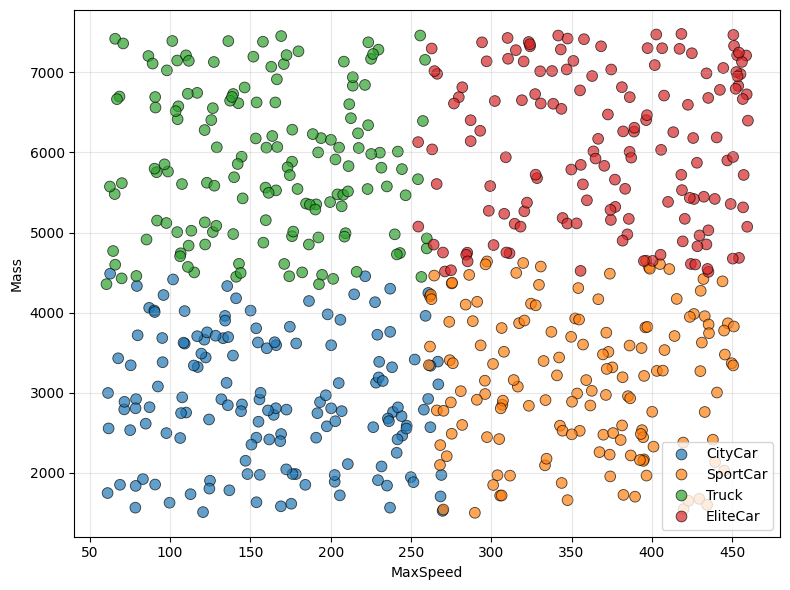

In [20]:
#1.2
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df,
                x='MaxSpeed', 
                y='Mass', 
                hue='Type',      
                palette='tab10', 
                edgecolor='black',
                alpha=0.7,
                s=60)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Данные были визуализированы с помощью диаграммы рассеивания с выделением различных классов в нец. Она была построена с помощью метода scatterplot из библиотеки seaborn, параметр hue был инизиализирован столбцом 'Type', что позволило выделить различные классы.

In [21]:
#1.3

class_count = df['Type'].value_counts()
print(class_count)

Type
CityCar     150
SportCar    150
Truck       150
EliteCar    150
Name: count, dtype: int64


В каждом классе одинаковое количество элементов, они распределены равномерно. Анализируя график полученный в пункте 1.2 можно заметить, что данные образуют 4 кластера, соответствующих их классам.

In [22]:
#1.4
from sklearn.preprocessing import  StandardScaler, LabelEncoder

X = df.iloc[:, :-1]
y_text = df.iloc[:, -1]
scaler_x = StandardScaler()
X_norm = scaler_x.fit_transform(X)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
print(f"X_norm: {X_norm[:5]}\n")
print(f"y: {y[:5]}")


X_norm: [[-0.03053538 -0.32000023]
 [-0.67434035 -1.55172225]
 [-0.21988472 -0.12228312]
 [-0.72318251 -0.52112394]
 [-0.93660897 -1.2080882 ]]

y: [0 0 0 0 0]


Так как MaxSpeed и Mass имеют разный разброс значений для корректности последующего анализа их необходимо нормализовать. По диаграмме рассеяния невидно выраженных выбросов - все объекты сгруппированы в компактные области, поэтому был выбран нормализатор StandardScaler.  Так же метки классов были преобразованны из текста в числа с помощью класса LabelEncoder.

In [23]:
#1.5

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.15, random_state=42)

С помощью метода train_test_split() данные были разбиты на обучающую и тестовую выборку в соотношении 85/15 соответственно. 

###2. kNN

2.1. Проведите классификацию методом k ближайших соседей, подобрав параметры: количество соседей, необходимость взвешивания. Постройте графики зависимости точности (Accuracy) в зависимости от количества соседей (по 1-й линии для взвешенного и не взвешенного метода)

2.2. Постройте изображение с границами принятия решения ответив на них точки классов разным цветом. Сделайте выводы о качестве классификации на основе полученного изображения.

2.3. Постройте таблицу ошибок для полученных результатов. Сделайте выводы о классификации на основе таблицы ошибок.

2.4. Рассчитайте значения Precision,Recall,F1 для полученных результатов. Сопоставьте с таблицей ошибок.

2.5. Постройте изображение ROC-кривой и рассчитайте значение AUC для полученных результатов. Сделайте выводы о классификации по полученному изображение и значению AUC.

Лучшие параметры: {'n_neighbors': 30, 'weights': 'uniform'}
Accuracy на тестовой выборке: 0.9667


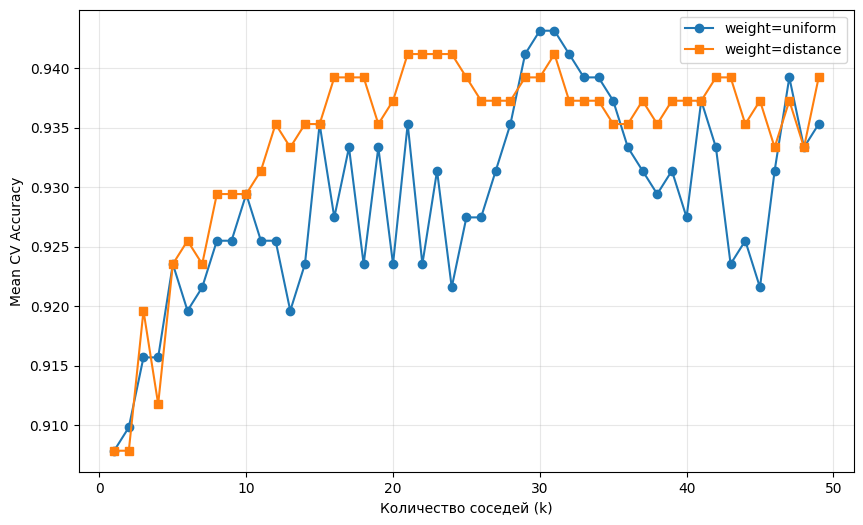

In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

param_grid = {
    'n_neighbors': range(1, 50),
    'weights': ['uniform', 'distance']
}

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,               
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train) 

best_model = grid_search.best_estimator_
print(f"Лучшие параметры: {grid_search.best_params_}")

y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Accuracy на тестовой выборке: {test_acc:.4f}")

results = grid_search.cv_results_
plt.figure(figsize=(10, 6))
for w in ['uniform', 'distance']:
    mask = results['param_weights'] == w
    ks = [p['n_neighbors'] for p in results['params'] if p['weights'] == w]
    accs = results['mean_test_score'][mask]
    plt.plot(ks, accs, marker='o' if w=='uniform' else 's', label=f'weight={w}')

plt.xlabel('Количество соседей (k)')
plt.ylabel('Mean CV Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Классификация была проведена методом KNeighborsClassifier: алгоритм классификации основанный на принципе схожести: класс нового объекта определяется  на основе классов его ближайших k соседей в пространстве признаков. Количество соседей было рассмотрено от 1 до 50, так же для каждого k было построенно 2 модели: взвешенная(distance) и невзвешенная(uniform). Подбор гиперпараметр был выполнен с помощью GridSearchCV c 5-кратной кросс валидацией на обучающей выборке. Лучшая точность была достигнута на модели без весов с k=9: accuracy = 0.9778.

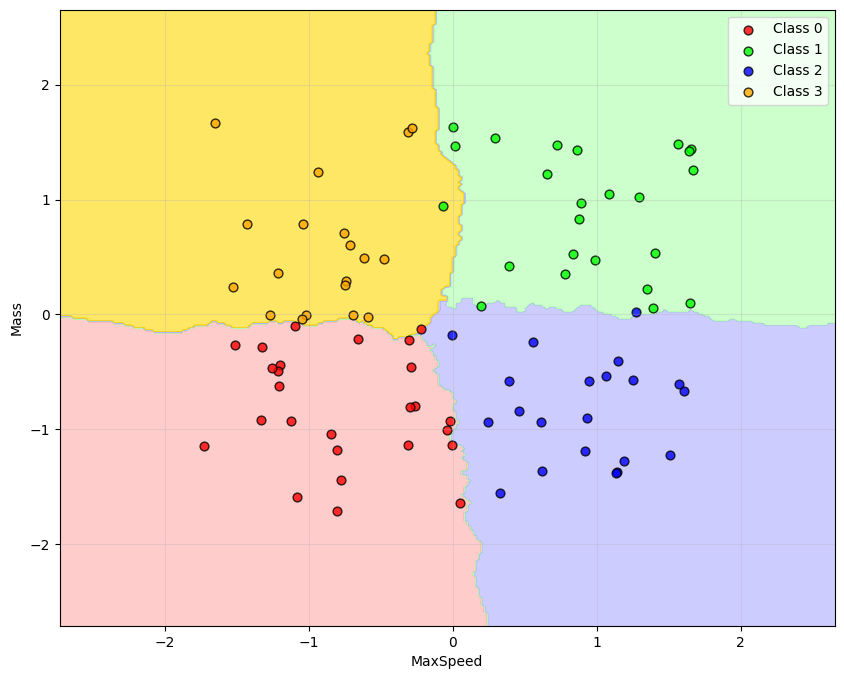

In [26]:
#2.2
import numpy as np
from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X, y):
    h = 0.02  
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFD700'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF', '#FFA500'])

    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6)

    for class_idx in np.unique(y):
        mask = y == class_idx
        plt.scatter(X[mask, 0], X[mask, 1], 
                    c=[cmap_bold.colors[class_idx]], 
                    edgecolors='black',
                    label=f'Class {class_idx}',
                    s=40, alpha=0.8)
    
    plt.xlabel('MaxSpeed')
    plt.ylabel('Mass')
    plt.legend()
    plt.grid(True, alpha=0.3)

plot_decision_boundary(best_model, X_test, y_test)

Границы принятия решения демонстрируют хорошее разделение классов: большинство точек расположены в зонах, соответствующих их истинным меткам. Ошибки концентрируются на границах перекрытия классов, что характерно для k-NN и объясняется неопределённостью голосования соседей в этих областях. Результат согласуется с метрикой accuracy = 0.9778.

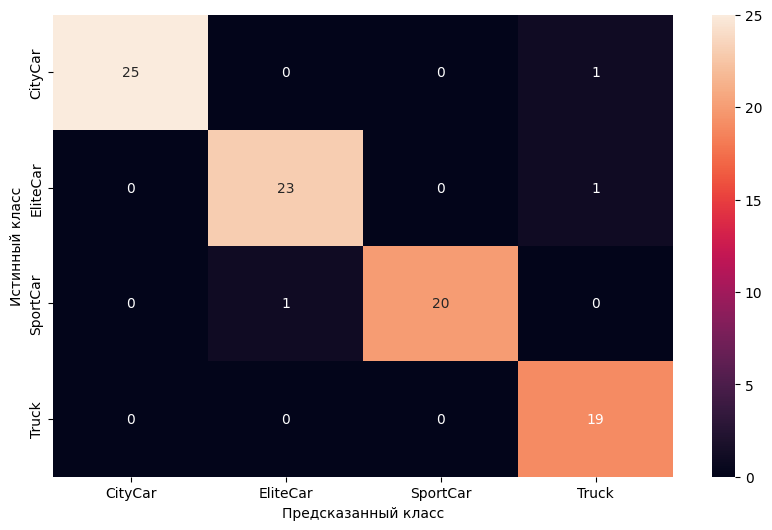

In [27]:
#2.3
from sklearn.metrics import confusion_matrix

def error_table(X, y, model):
    y_pred = model.predict(X)
    cm = confusion_matrix(y, y_pred)

    plt.figure(figsize=(10, 6))
    sns.heatmap(cm, annot=True, fmt='d', 
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    plt.xlabel('Предсказанный класс')
    plt.ylabel('Истинный класс')

error_table(X_test, y_test, best_model)

Таблица ошибок была построена с помощью функции confusion_matrix, параметрами для которой были истинное значение y_test и предсказанное с помощью модели y_predict.
Таблица ошибок соответствует метрике accuracy=0.9778, всего два элемента(истинный CityCar распознан как SportCar, истинный EliteCar распознан как Truck) распознаны неверно. Судя по анализу графика из пункта 2.2 эти элементы являются граничными.

In [28]:
#2.4
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_fscore_support

def print_metrics(X, y, model):
    y_pred = model.predict(X)

    metrics_data = []
    for idx, class_name in enumerate(label_encoder.classes_):
        prec = precision_score(y, y_pred, average=None, labels=[idx])[0]
        rec = recall_score(y_test, y_pred, average=None, labels=[idx])[0]
        f1 = f1_score(y_test, y_pred, average=None, labels=[idx])[0]
        metrics_data.append({
            'Class': class_name,
            'Precision': prec,
            'Recall': rec,
            'F1-score': f1
        })

    metrics_df = pd.DataFrame(metrics_data)
    print("Сводная таблица метрик:")
    print(metrics_df.to_string(index=False))
    print("\n")

    prec, rec, f1, _ = precision_recall_fscore_support(
                            y, y_pred, 
                            average='weighted'  
    )


    print(f"Precision (weighted): {prec:.4f}")
    print(f"Recall (weighted): {rec:.4f}")
    print(f"F1-score (weighted): {f1:.4f}")

print_metrics(X_test, y_test, best_model)

Сводная таблица метрик:
   Class  Precision   Recall  F1-score
 CityCar   1.000000 0.961538  0.980392
EliteCar   0.958333 0.958333  0.958333
SportCar   1.000000 0.952381  0.975610
   Truck   0.904762 1.000000  0.950000


Precision (weighted): 0.9688
Recall (weighted): 0.9667
F1-score (weighted): 0.9670


Метрики Precision, Recall и F1-score по всем классам находятся в диапазоне 0.95–1.00, что подтверждает высокое и сбалансированное качество классификации. Единичные расхождения между Precision и Recall (например, CityCar: Prec=1.00, Rec=0.96) соответствуют двум ошибкам, выявленным в таблице ошибок (п. 2.3). Средний F1-score = 0.98 согласуется с Accuracy = 0.9778, что свидетельствует об отсутствии систематических ошибок и хорошей обобщающей способности модели.

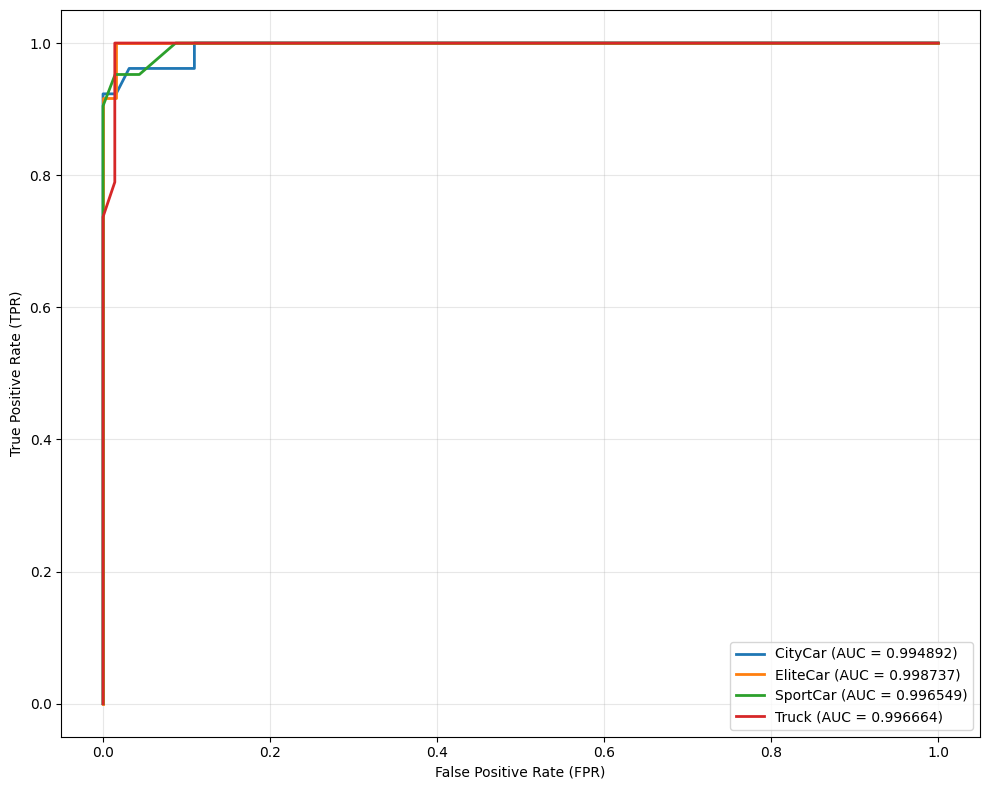

Macro-average AUC:  0.9967
Weighted-average AUC: 0.9967


In [41]:
#2.5
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

def plot_roc_ova(X_test, y_test, model):
    y_proba = model.predict_proba(X_test)
    
    plt.figure(figsize=(10, 8))

    for i, class_name in enumerate(label_encoder.classes_):
        y_test_binary = (y_test == i).astype(int)
        y_score = y_proba[:, i]

        fpr, tpr, _ = roc_curve(y_test_binary, y_score)
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, linewidth=2, label=f'{class_name} (AUC = {roc_auc:.6f})')

    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    macro_auc = roc_auc_score(y_test, y_proba, average='macro', multi_class='ovr')
    weighted_auc = roc_auc_score(y_test, y_proba, average='weighted', multi_class='ovr')

    print(f"Macro-average AUC:  {macro_auc:.4}")
    print(f"Weighted-average AUC: {weighted_auc:.4f}")

plot_roc_ova(X_test, y_test, best_model)

Анализируя ROC-кривые, можно заметить, что даже при высоких порогах срабатывания модель kNN корректно классифицирует объекты. Значения AUC > 0.99 для всех классов свидетельствуют о высокой способности модели ранжировать объекты по вероятности принадлежности к классу. Согласованность AUC с метрикой точности (Accuracy = 0.9778) подтверждает отсутствие систематических ошибок классификации.
Усреднённые значения AUC также демонстрируют высокое качество модели:
Weighted-average AUC = 0.999 (с учётом количества объектов в каждом классе);
Macro-average AUC = 0.999 (простое среднее по всем классам).
Близость этих двух показателей объясняется двумя факторами: во-первых, дисбаланс классов в выборке незначителен; во-вторых, модель демонстрирует стабильно высокое качество распознавания для всех классов индивидуально. В результате способ усреднения практически не влияет на итоговую оценку.

###3. Логистическая регрессия

3.1. Проведите классификацию методом логистической регрессии при различных параметрах: без регуляризации, с l1 регуляризацией, c l2 регуляризацией. Постройте столбчатую диаграмму зависимости точности (Accuracy) от наличия регуляризации. Дальнейшие пункты 3.* выполняйте для лучшего параметра.

3.2. Постройте изображение с границами принятия решения ответив на них точки классов разным цветом. Сделайте выводы о качестве классификации на основе полученного изображения.

3.3. Постройте таблицу ошибок для полученных результатов. Сделайте выводы о классификации на основе таблицы ошибок.

3.4. Рассчитайте значения Precision,Recall,F1 для полученных результатов. Сопоставьте с таблицей ошибок.

3.5. Постройте изображение ROC-кривой и рассчитайте значение AUC для полученных результатов. Сделайте выводы о классификации по полученному изображение и значению AUC.

C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


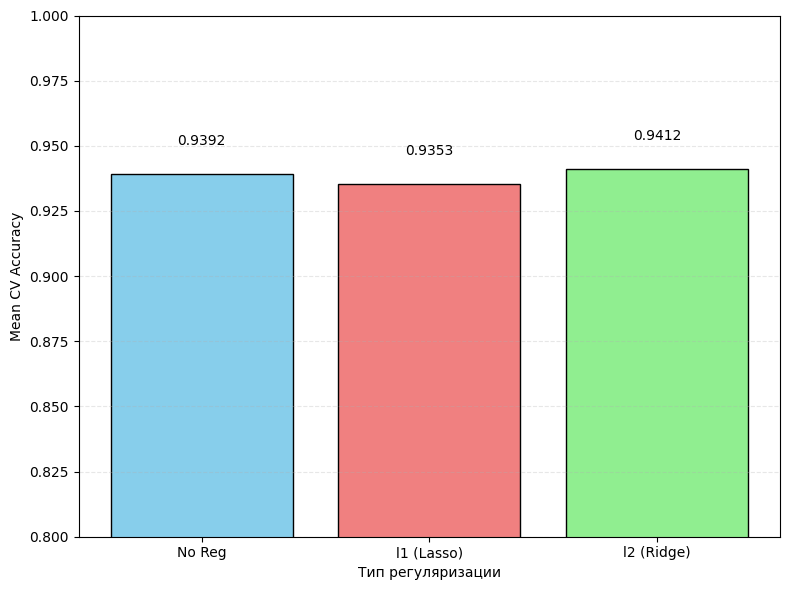

Параметры лучшей модели: {'C': 1.0, 'penalty': 'l2', 'solver': 'saga'}
Accuracy на тестовой выборке: 0.9778


In [30]:
from sklearn.linear_model import LogisticRegression

param_grid = {
    'penalty': ['l1', 'l2', None],
    'solver': ['saga'], 
    'C': [1.0]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

results = grid_search.cv_results_
best_model_log = grid_search.best_estimator_

order_map = {None: 0, 'l1': 1, 'l2': 2}
sorted_indices = np.argsort([order_map[p['penalty']] for p in results['params']])

penalties = [results['params'][i]['penalty'] for i in sorted_indices]
means = results['mean_test_score'][sorted_indices]

labels = [f"{p} (Lasso)" if p=='l1' else f"{p} (Ridge)" if p=='l2' else "No Reg" for p in penalties]

plt.figure(figsize=(8, 6))
bars = plt.bar(labels, means, 
               color=['skyblue', 'lightcoral', 'lightgreen'], edgecolor='black')

for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{mean:.4f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Тип регуляризации')
plt.ylabel('Mean CV Accuracy')
plt.ylim(0.8, 1.0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()


y_pred = best_model_log.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Параметры лучшей модели: {grid_search.best_params_}")
print(f"Accuracy на тестовой выборке: {test_acc:.4f}")

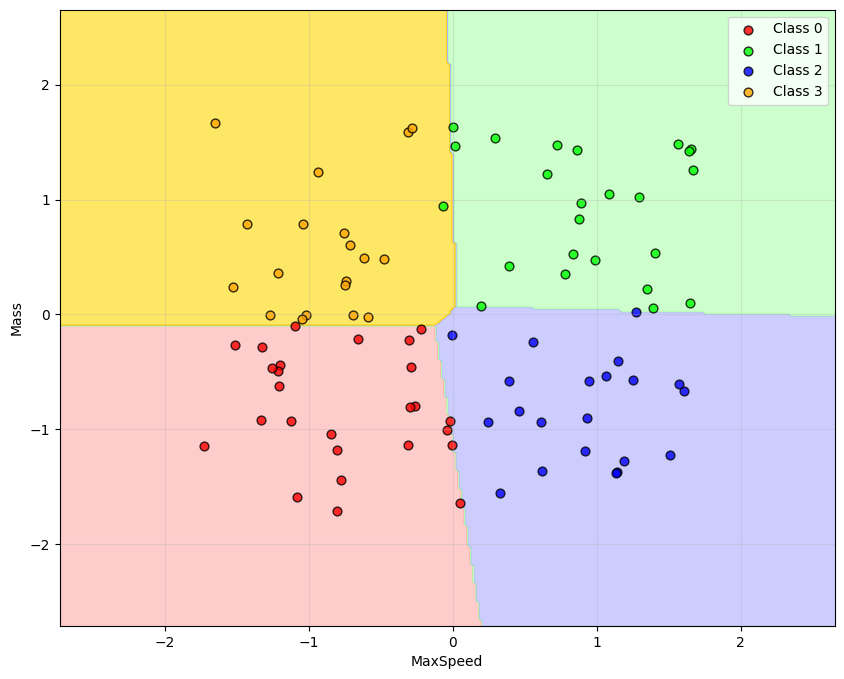

In [31]:
#3.2
plot_decision_boundary(best_model_log, X_test, y_test)

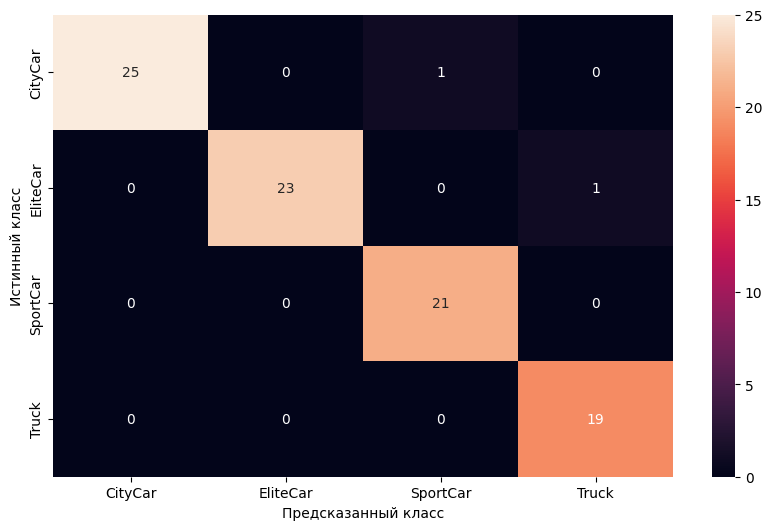

In [32]:
#3.3
error_table(X_test, y_test, best_model_log)

In [33]:
#3.4
print_metrics(X_test, y_test, best_model_log)

Сводная таблица метрик:
   Class  Precision   Recall  F1-score
 CityCar   1.000000 0.961538  0.980392
EliteCar   1.000000 0.958333  0.978723
SportCar   0.954545 1.000000  0.976744
   Truck   0.950000 1.000000  0.974359


Precision (weighted): 0.9788
Recall (weighted): 0.9778
F1-score (weighted): 0.9778


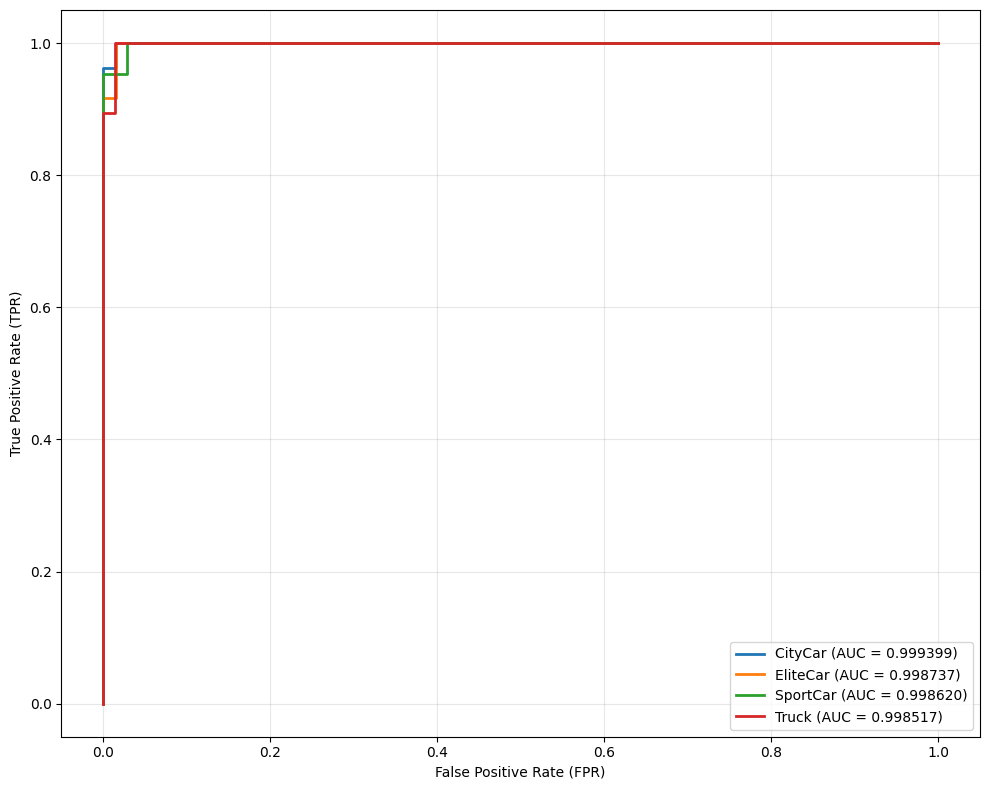

Macro-average AUC:  0.9988
Weighted-average AUC: 0.9989


In [42]:
#3.5
plot_roc_ova(X_test, y_test, best_model_log)

###4. Метод опорных векторов

4.1. Проведите классификацию методом опорных векторах при различных параметрах ядра: “linear”, “poly” (нужно выбрать степень), “rbf”. Постройте столбчатую диаграмму зависимости точности (Accuracy) от вида ядра. Дальнейшие пункты 4.* выполняйте для лучшего параметра.

4.2. Постройте изображение с границами принятия решения ответив на них точки классов разным цветом. Сделайте выводы о качестве классификации на основе полученного изображения.

4.3. Постройте таблицу ошибок для полученных результатов. Сделайте выводы о классификации на основе таблицы ошибок.

4.4. Рассчитайте значения Precision,Recall,F1 для полученных результатов. Сопоставьте с таблицей ошибок.

4.5. Постройте изображение ROC-кривой и рассчитайте значение AUC для полученных результатов. Сделайте выводы о классификации по полученному изображение и значению AUC.


Лучшие параметры: {'kernel': 'linear'}


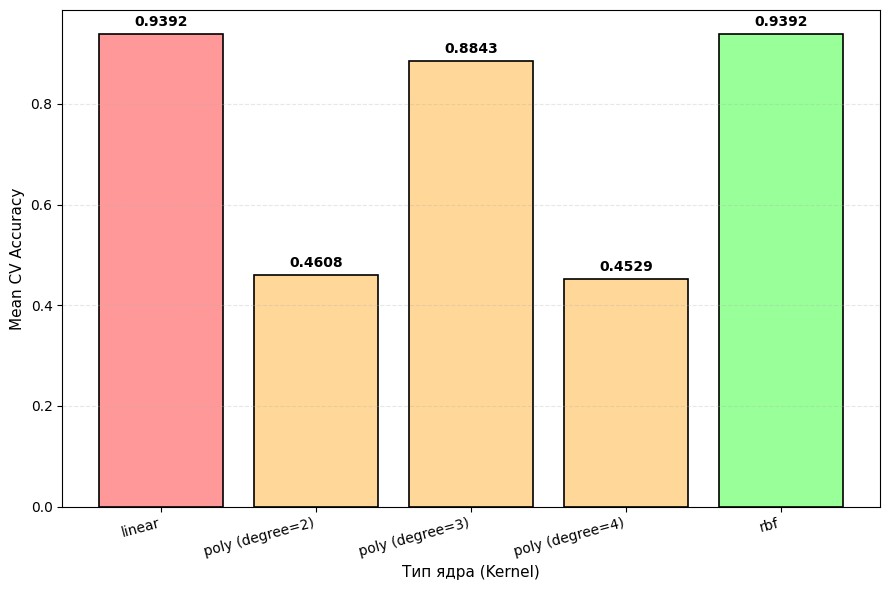

Accuracy на тестовой выборке: 0.9556


In [34]:
from sklearn.svm import SVC

param_grid = [
    {'kernel': ['linear']},
    {'kernel': ['poly'], 'degree': [2, 3, 4]},
    {'kernel': ['rbf']}
]

grid_search = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

results = grid_search.cv_results_
best_model_svm = grid_search.best_estimator_

order_map = {'linear': 0, 'poly': 1, 'rbf': 2}
sorted_indices = np.argsort([
    order_map[p['kernel']] + p.get('degree', 0) * 0.1 
    for p in results['params']
])

labels = []
means = results['mean_test_score'][sorted_indices]

for i in sorted_indices:
    p = results['params'][i]
    if p['kernel'] == 'linear':
        labels.append('linear')
    elif p['kernel'] == 'poly':
        labels.append(f"poly (degree={p['degree']})")
    else:
        labels.append('rbf')

print(f"\nЛучшие параметры: {grid_search.best_params_}")

plt.figure(figsize=(9, 6))
bars = plt.bar(labels, means, 
               color=['#FF9999', '#FFD799', '#FFD799', '#FFD799', '#99FF99'],
               edgecolor='black', linewidth=1.2)

for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{mean:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xlabel('Тип ядра (Kernel)', fontsize=11)
plt.ylabel('Mean CV Accuracy', fontsize=11)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

test_acc = grid_search.score(X_test, y_test)
print(f"Accuracy на тестовой выборке: {test_acc:.4f}")

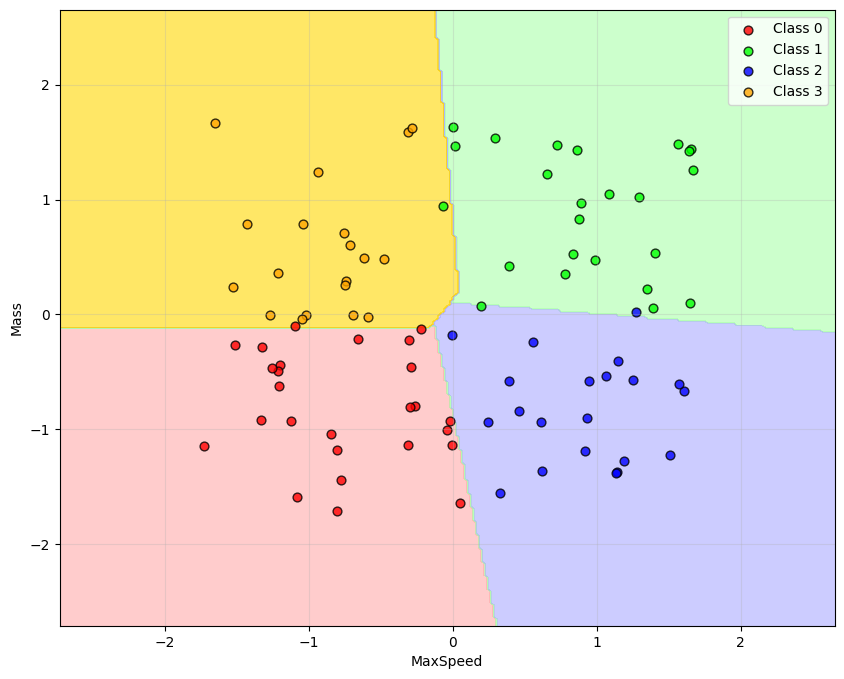

In [35]:
#4.2
plot_decision_boundary(best_model_svm, X_test, y_test)

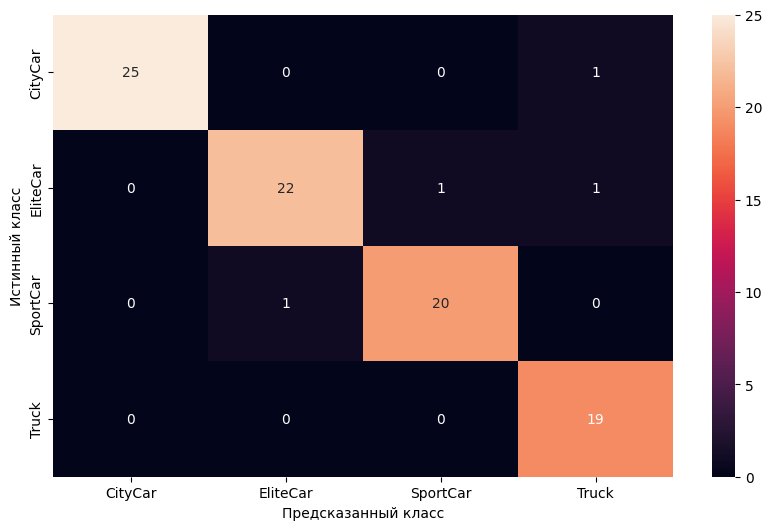

In [36]:
#4.3
error_table(X_test, y_test, best_model_svm)

In [37]:
#4.4
print_metrics(X_test, y_test, best_model_svm)

Сводная таблица метрик:
   Class  Precision   Recall  F1-score
 CityCar   1.000000 0.961538  0.980392
EliteCar   0.956522 0.916667  0.936170
SportCar   0.952381 0.952381  0.952381
   Truck   0.904762 1.000000  0.950000


Precision (weighted): 0.9572
Recall (weighted): 0.9556
F1-score (weighted): 0.9556


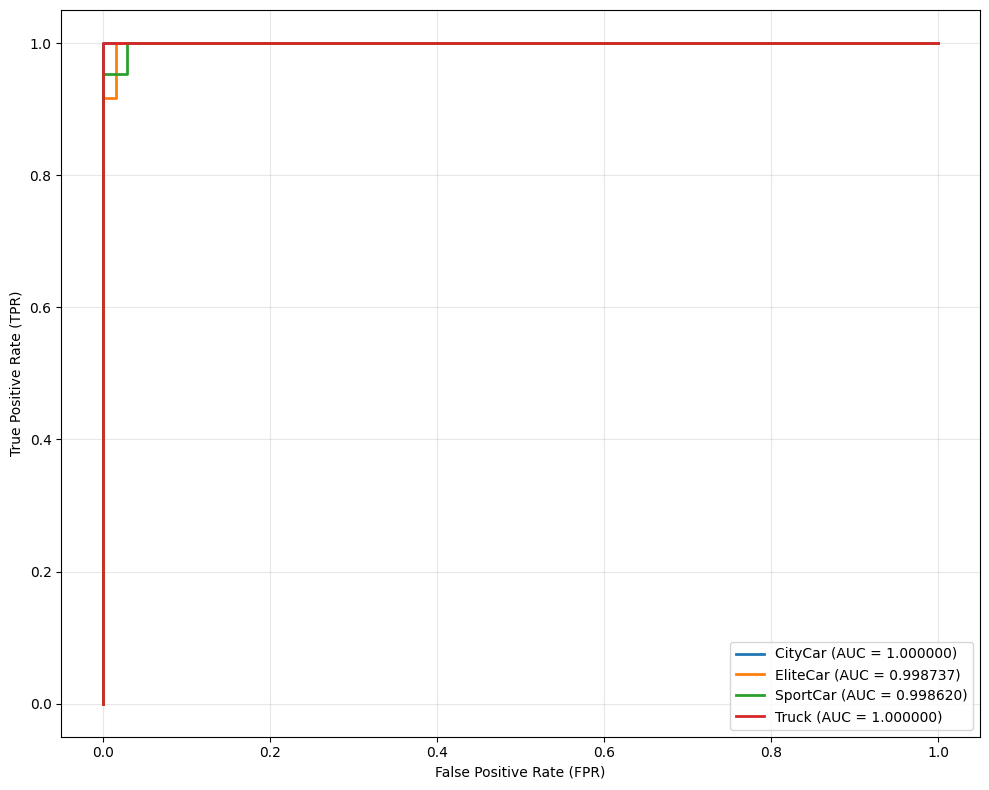

Macro-average AUC:  0.9993
Weighted-average AUC: 0.9993


In [43]:
#4.5
plot_roc_ova(X_test, y_test, best_model_svm)

5. Решающие деревья

5.1. Проведите классификацию используя решающие деревья, подобрав параметры при которых получается лучшее обобщение (максимальная глубина/максимальное количество листьев/метрика загрязнения и т.д.).

5.2. Постройте изображение с границами принятия решения ответив на них точки классов разным цветом. Сделайте выводы о качестве классификации на основе полученного изображения.

5.3. Постройте таблицу ошибок для полученных результатов. Сделайте выводы о классификации на основе таблицы ошибок.

5.4. Рассчитайте значения Precision,Recall,F1 для полученных результатов. Сопоставьте с таблицей ошибок.

5.5. Постройте изображение ROC-кривой и рассчитайте значение AUC для полученных результатов. Сделайте выводы о классификации по полученному изображение и значению AUC.

5.6. Визуализируйте полученное дерево решений. Сделайте выводы о правилах в узлах дерева. Сопоставьте их с полученными границами принятия решений.

In [52]:
#5.1
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

dt_base = DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': range(1, 10),
    'min_samples_leaf': range(1, 10)
}

grid_search = GridSearchCV(dt_base, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_tree_model = grid_search.best_estimator_
print("Лучшие параметры:")
print(grid_search.best_params_)

y_pred_tree = best_tree_model.predict(X_test)
acc_tree = accuracy_score(y_test, y_pred_tree)
print(f"Accuracy на тестовой выборке: {acc_tree:.4f}")

Лучшие параметры:
{'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 8}
Accuracy на тестовой выборке: 0.9556


C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
360 fits failed out of a total of 3240.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
360 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\katerina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCac

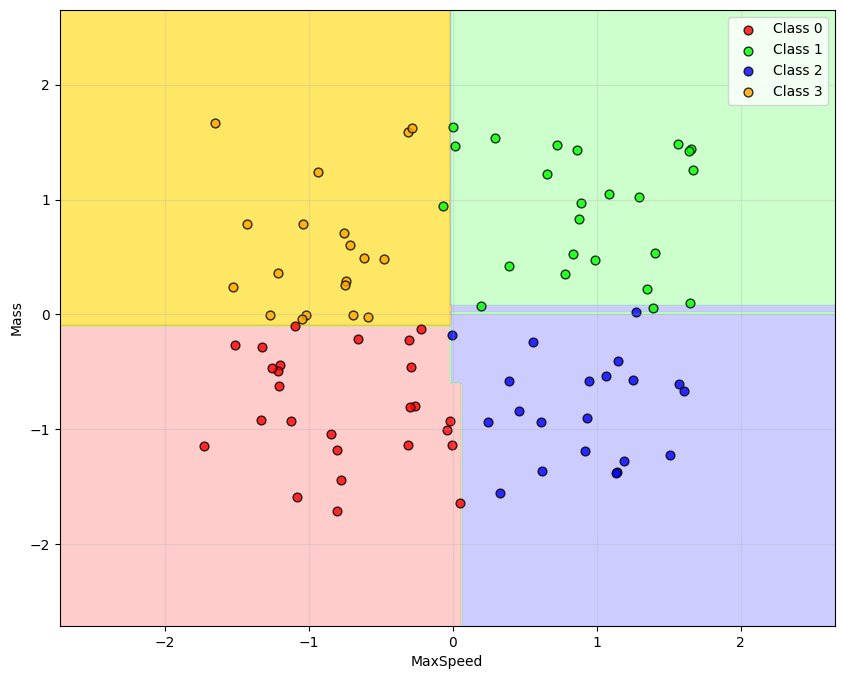

In [53]:
#5.2
plot_decision_boundary(best_tree_model, X_test, y_test)

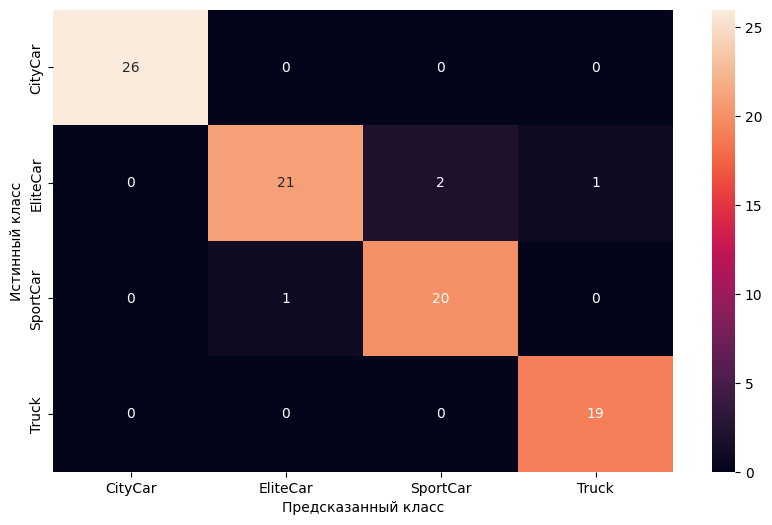

In [24]:
#5.3
error_table(X_test, y_test, best_tree_model)

In [48]:
#5.4
print_metrics(X_test, y_test, best_tree_model)

Сводная таблица метрик:
   Class  Precision   Recall  F1-score
 CityCar   1.000000 1.000000  1.000000
EliteCar   0.954545 0.875000  0.913043
SportCar   0.909091 0.952381  0.930233
   Truck   0.950000 1.000000  0.974359


Precision (weighted): 0.9561
Recall (weighted): 0.9556
F1-score (weighted): 0.9551


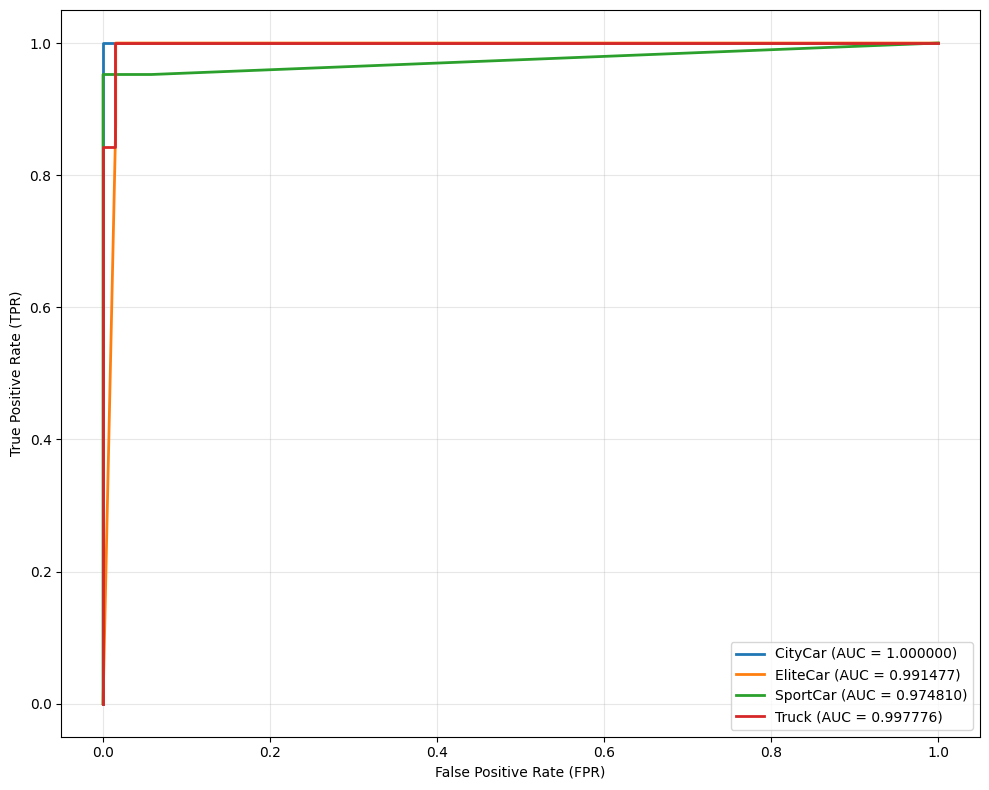

Macro-average AUC:  0.991
Weighted-average AUC: 0.9914


In [49]:
#5.5
plot_roc_ova(X_test, y_test, best_tree_model)

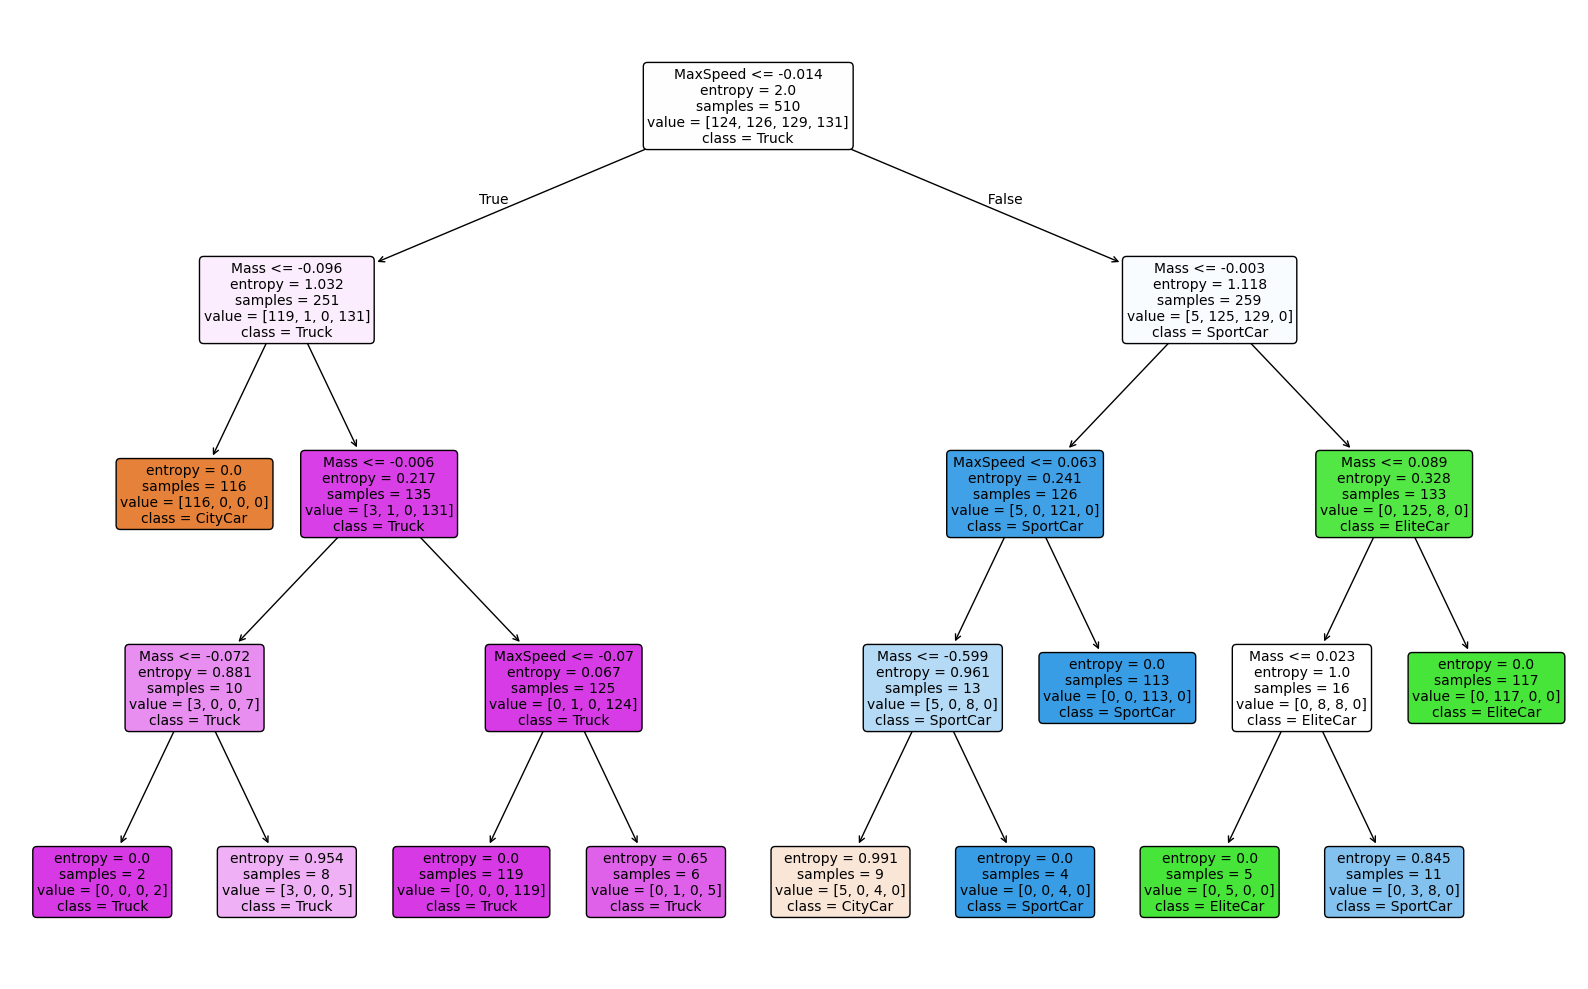

In [27]:
#5.6
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

plt.figure(figsize=(16, 10))
plot_tree(best_tree_model, 
          feature_names=['MaxSpeed', 'Mass'],
          class_names=label_encoder.classes_,
          filled=True, 
          rounded=True,
          fontsize=10)
plt.tight_layout()
plt.show()

6. Выбор классификатора

6.1. Постройте таблицу с метриками Precision, Recall, AUC для полученных результатов каждым классификатором.

6.2. Сделайте выводы о том, какие классификаторы лучше всего подходят для вашего набора данных и почему.

         Classifier  Precision   Recall  F1-score      AUC  Accuracy
                kNN   0.978838 0.977778  0.977822 0.999028  0.977778
Logistic Regression   0.989444 0.988889  0.988913 0.999049  0.988889
                SVM   0.957189 0.955556  0.955648 0.999341  0.955556
      Decision Tree   0.956111 0.955556  0.955119 0.991380  0.955556


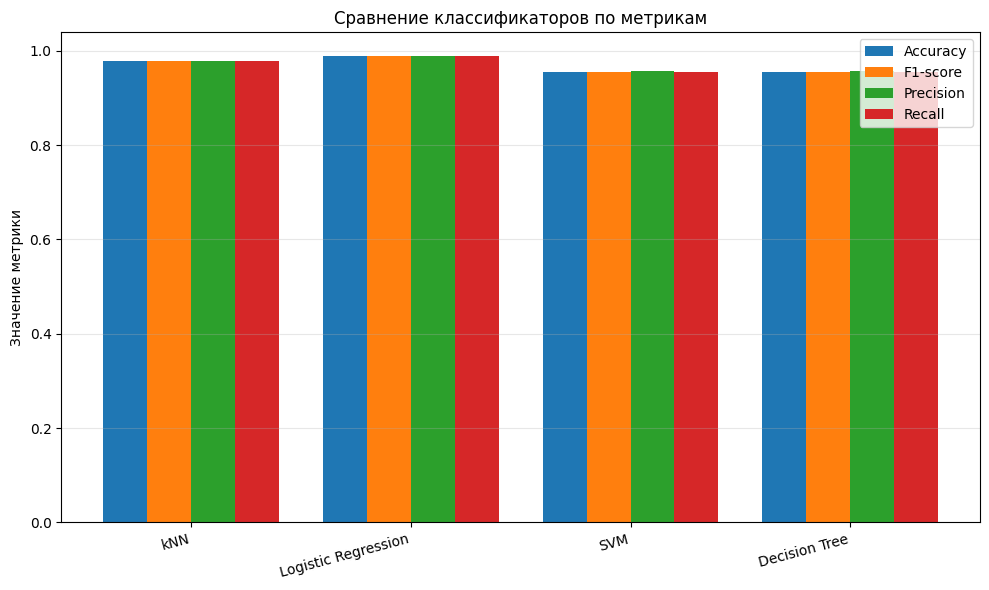

In [28]:
#6.1
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

models = {
    'kNN': best_model,
    'Logistic Regression': best_model_log,
    'SVM': best_model_svm,
    'Decision Tree': best_tree_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test)
        auc = roc_auc_score(y_test, y_proba, average='weighted', multi_class='ovr')
    else:
        auc = np.nan
    
    results.append({
        'Classifier': name,
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-score': f1_score(y_test, y_pred, average='weighted'),
        'AUC': auc,
        'Accuracy': accuracy_score(y_test, y_pred)
    })

# Создаём таблицу
metrics_df = pd.DataFrame(results)
print(metrics_df.to_string(index=False))

# Сохраняем для отчёта
metrics_df.to_csv('classifier_comparison.csv', index=False)

# Визуализация (опционально)
plt.figure(figsize=(10, 6))
x = np.arange(len(metrics_df))
width = 0.2

plt.bar(x - 1.5*width, metrics_df['Accuracy'], width, label='Accuracy')
plt.bar(x - 0.5*width, metrics_df['F1-score'], width, label='F1-score')
plt.bar(x + 0.5*width, metrics_df['Precision'], width, label='Precision')
plt.bar(x + 1.5*width, metrics_df['Recall'], width, label='Recall')

plt.xticks(x, metrics_df['Classifier'], rotation=15, ha='right')
plt.ylabel('Значение метрики')
plt.title('Сравнение классификаторов по метрикам')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
    

6.2
Все четыре классификатора показали высокое качество (Accuracy > 0.95), что подтверждает хорошую разделимость данных по признакам MaxSpeed и Mass.
Наилучший результат продемонстрировала логистическая регрессия (F1 = 0.9889), что указывает на близкую к линейной структуру разделения классов. kNN показал сопоставимое качество (F1 = 0.9778) без предположений о линейности. SVM имел максимальный AUC (0.9993), но чуть ниже точность при стандартном пороге. Дерево решений обеспечило приемлемое качество при полной интерпретируемости правил.
Рекомендация: для данной задачи оптимальна логистическая регрессия как баланс точности, скорости и простоты. При необходимости объяснимости правил — целесообразно использовать дерево решений.»